<a href="https://colab.research.google.com/github/amrutha-pullaikodi/Bank-system-using-opps/blob/main/Regression_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Load the California Housing dataset using the fetch_california_housing function
from sklearn.



In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#Load the California Housing dataset
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing()
print("Target", data.target_names)
data.feature_names


Target ['MedHouseVal']


['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude']

Convert the dataset into a pandas DataFrame for easier handling. Handle missing values (if any) and perform necessary feature scaling (e.g.standardization).

In [6]:
#Convert dataset into a Pandas DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)
df.head()
df.columns

# Add target column (MedHouseVal)
df['MedHouseVal'] = data.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [8]:
#check for null value
df.isnull().sum()
#check the information about the table
df.info()
#take the statistical information
df.describe()
#drop duplicates if any
df.drop_duplicates(inplace=True)
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


(20640, 9)

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')


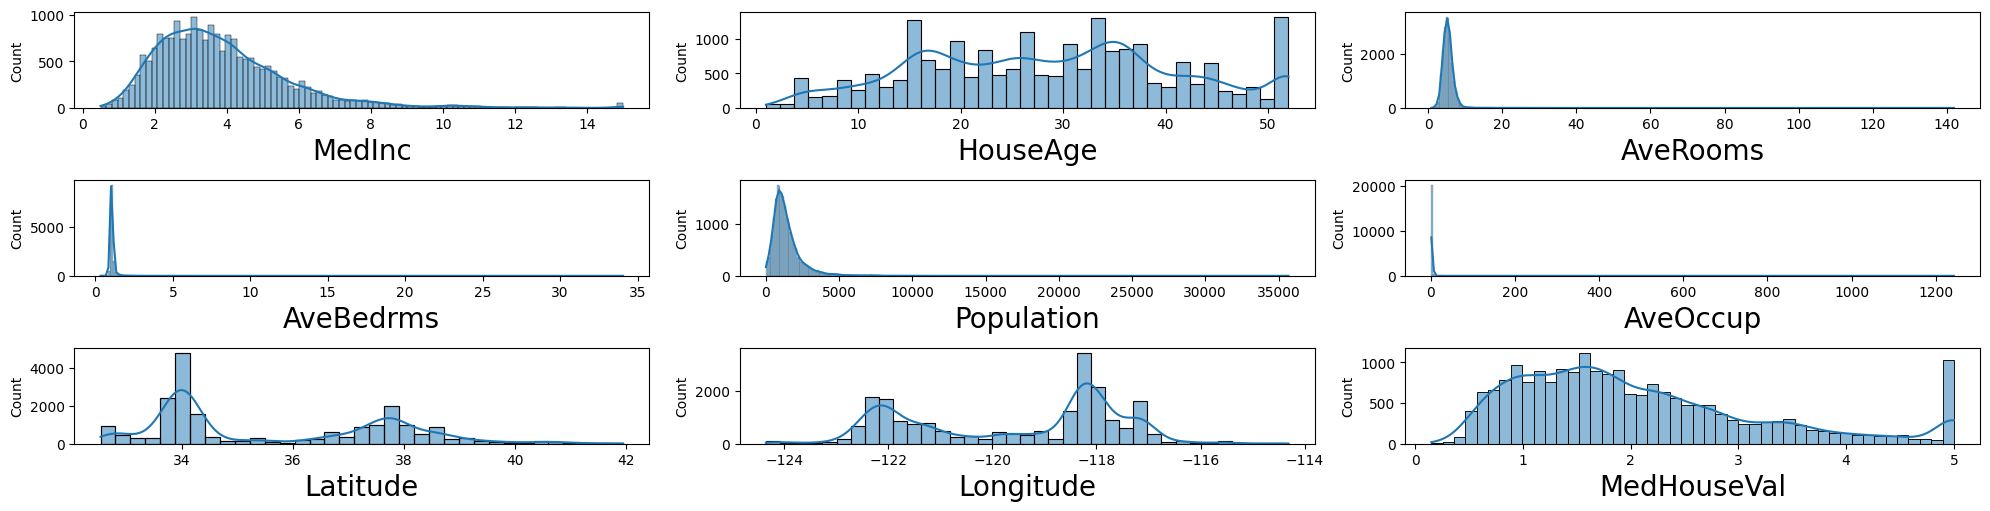

In [7]:
#slecting the numerical columns to plot histogram
import seaborn as sns
cols=df.select_dtypes(include=np.number)
print(cols.columns)
plt.figure(figsize=(20,8))
plotnumber=1
for column in cols:
  if plotnumber<=9:
    ax=plt.subplot(5,3,plotnumber)
    sns.histplot(cols[column],kde=True)
    plt.xlabel(column,fontsize=20)
  plotnumber+=1
plt.tight_layout()



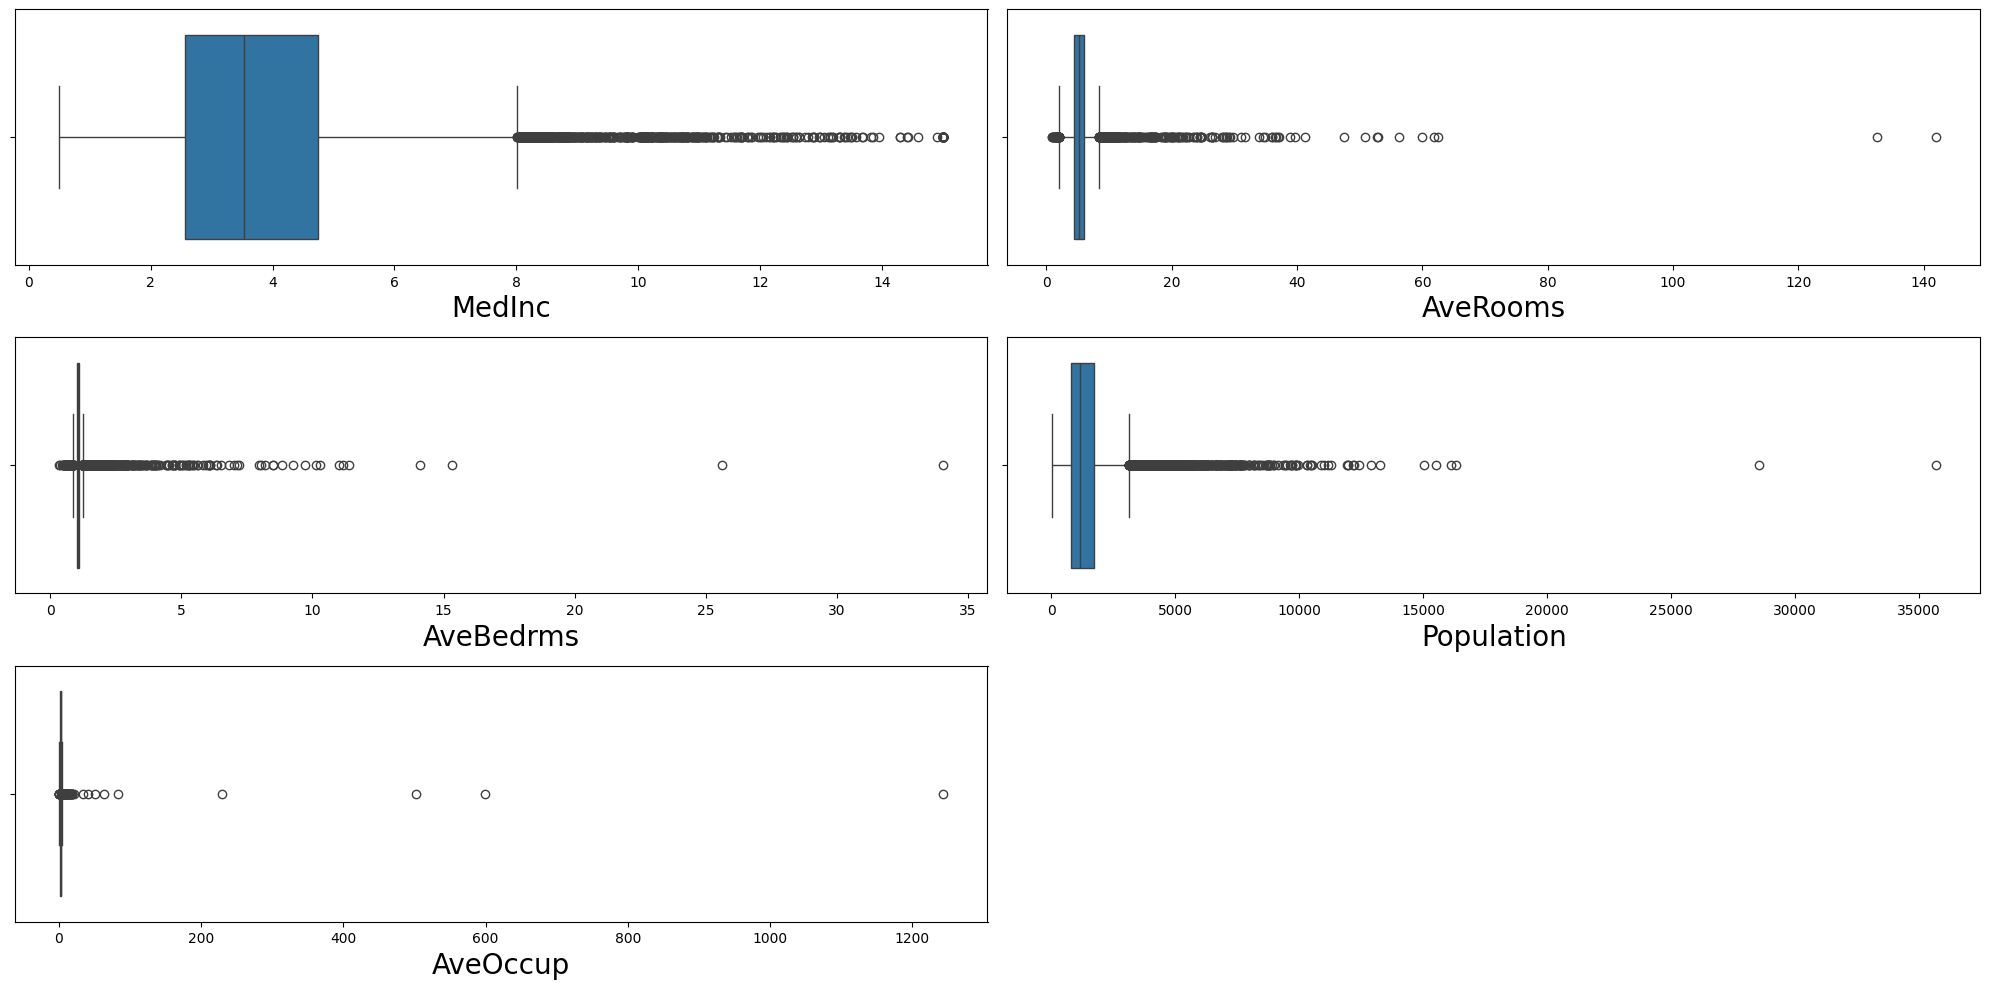

In [9]:
outlier_cols=['MedInc', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup']
plt.figure(figsize=(20,10))
plotnumber=1
for column in outlier_cols:
  if plotnumber<=9:
    ax=plt.subplot(3,2,plotnumber)
    sns.boxplot(x=column,data=df)
    plt.xlabel(column,fontsize=20)
  plotnumber+=1
plt.tight_layout()


In [10]:
#Separate features and target variable

X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

#Perform feature scaling using StandardScaler
scaler=StandardScaler()
X_std=scaler.fit_transform(X)
X_std=pd.DataFrame(X_std)
X_std.describe()
#

,0,1,2,3,4,5,6,7
count,2.064000e+04,2.064000e+04,2.064000e+04,2.064000e+04,2.064000e+04,20640.000000,2.064000e+04,2.064000e+04
mean,5.508083e-17,4.406467e-17,7.711317e-17,-1.005225e-16,-1.101617e-17,0.000000,2.247298e-15,-8.603626e-15
std,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024,1.000024e+00,1.000024e+00
min,-1.774299e+00,-2.196180e+00,-1.852319e+00,-1.610768e+00,-1.256123e+00,-0.229000,-1.447568e+00,-2.385992e+00
25%,-6.881186e-01,-8.453931e-01,-3.994496e-01,-1.911716e-01,-5.638089e-01,-0.061711,-7.967887e-01,-1.113209e+00
50%,-1.767951e-01,2.864572e-02,-8.078489e-02,-1.010650e-01,-2.291318e-01,-0.024316,-6.422871e-01,5.389137e-01
75%,4.593063e-01,6.643103e-01,2.519615e-01,6.015869e-03,2.644949e-01,0.020375,9.729566e-01,7.784964e-01
max,5.858286e+00,1.856182e+00,5.516324e+01,6.957171e+01,3.025033e+01,119.419103,2.958068e+00,2.625280e+00


In [12]:
#create a function to remove outlier
def remove_outliers_iqr(data, column):
  q1,q2,q3 = np.percentile(data[column],[25,50,75])
  print("q1,q2,q3 is :",q1,q2,q3)
  IQR = q3-q1
  print("IQR is :" ,IQR)
  lower_limit = q1-(1.5*IQR)
  upper_limit = q3+(1.5*IQR)
  data[column]=np.where(data[column]>upper_limit,upper_limit,data[column]) # Capping the upper limit
  data[column]=np.where(data[column]<lower_limit,lower_limit,data[column]) # Flooring the lower limit

In [13]:
for column in outlier_cols:
  remove_outliers_iqr(df,column)

q1,q2,q3 is : 2.5633999999999997 3.5347999999999997 4.74325
IQR is : 2.17985
q1,q2,q3 is : 4.440716235896959 5.229128787878788 6.052380952380952
IQR is : 1.6116647164839932
q1,q2,q3 is : 1.006079046038478 1.048780487804878 1.099526066350711
IQR is : 0.09344702031223284
q1,q2,q3 is : 787.0 1166.0 1725.0
IQR is : 938.0
q1,q2,q3 is : 2.4297411475535755 2.818115654360196 3.2822609242736216
IQR is : 0.8525197767200461


● Explain the preprocessing steps you performed and justify why they are
necessary for this dataset.

1.Handling Missing Values: Checked for missing values using isnull().sum(). Missing numerical values, if any, were replaced with the median of their respective columns. Median imputation is preferred because it is less affected by extreme values. The dataset does not contain missing values.
2.Removed duplicate rowa using df.drop_duplicates(inplace=True)
3.Performed feature scaling using StandardScaler
4.Removed outliers

2. Regression Algorithm Implementation (5 marks):
● Implement the following regression algorithms:
○ Linear Regression
○ Decision Tree Regressor
○ Random Forest Regressor
○ Gradient Boosting Regressor
○ Support Vector Regressor (SVR)

○ Linear Regression

In [15]:
from sklearn.model_selection import train_test_split
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,  random_state=42, test_size=0.2
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
from sklearn.linear_model import LinearRegression
#  Train a Baseline Model (Linear Regression)
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)
# Display predictions
print("Actual Values:")
print(y_test.head())

print("Predicted Values:")
print(y_pred[:5])

Training data: (16512, 8)
Testing data: (4128, 8)
Actual Values:
20046    0.47700
3024     0.45800
15663    5.00001
20484    2.18600
9814     2.78000
Name: MedHouseVal, dtype: float64
Predicted Values:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]


Linear Regression tries to find the best-fitting straight-line relationship between input features and the target value. It learns how changes in the features are associated with changes in house prices.

In [39]:
# evaluation

mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print(f"MSE : {mse}")
print(f"RMSE : {rmse}")
print(f"MAE : {mae}")
print(f"r2_score : {r2}")

MSE : 0.35700403193386454
RMSE : 0.5974981438748279
MAE : 0.39859907695205254
r2_score : 0.7275628923016777


Decision Tree

In [17]:
from sklearn.tree import DecisionTreeRegressor
dtr = DecisionTreeRegressor(random_state=42)
dtr.fit(X_train, y_train)

y_pred_dtr = dtr.predict(X_test)
y_pred_dtr

# Display predictions
print("Actual Values:")
print(y_test.head())

print("Predicted Values:")
print(y_pred_dtr[:5])

Actual Values:
20046    0.47700
3024     0.45800
15663    5.00001
20484    2.18600
9814     2.78000
Name: MedHouseVal, dtype: float64
Predicted Values:
[0.414   1.203   5.00001 2.17    2.257  ]


In [38]:
#Evaluation
mse = mean_squared_error(y_test,y_pred_dtr)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test,y_pred_dtr)
r2 = r2_score(y_test,y_pred_dtr)

print(f"MSE : {mse}")
print(f"RMSE : {rmse}")
print(f"MAE : {mae}")
print(f"r2_score : {r2}")

MSE : 0.495235205629094
RMSE : 0.7037294974840077
MAE : 0.45467918846899225
r2_score : 0.622075845135081


House prices can depend on complex, non-linear relationships. Decision Trees can learn these patterns and are easy to interpret. However, a deep tree may overfit the training data.

Random Forest


In [18]:
from sklearn.ensemble import RandomForestRegressor
rfr=RandomForestRegressor()
rfr.fit(X_train,y_train)
y_pred_rfr = rfr.predict(X_test)
# Display predictions
print("Actual Values:")
print(y_test.head())

print("Predicted Values:")
print(y_pred_rfr[:5])


Actual Values:
20046    0.47700
3024     0.45800
15663    5.00001
20484    2.18600
9814     2.78000
Name: MedHouseVal, dtype: float64
Predicted Values:
[0.48663   0.70527   4.8414563 2.61453   2.2984   ]


In [37]:
#Evaluation
mse = mean_squared_error(y_test,y_pred_rfr)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test,y_pred_rfr)
r2 = r2_score(y_test,y_pred_rfr)

print(f"MSE : {mse}")
print(f"RMSE : {rmse}")
print(f"MAE : {mae}")
print(f"r2_score : {r2}")

MSE : 0.2540578908799802
RMSE : 0.5040415566994255
MAE : 0.3257672184835273
r2_score : 0.8061232064961666


House prices depend on several factors, such as income, location and house age.
These factors may have complex, non-linear relationships.
Random Forest can capture these relationships.
Combining multiple trees generally gives more stable predictions than using a single Decision Tree.

○ Gradient Boosting Regressor

In [35]:
from sklearn.ensemble import GradientBoostingRegressor
gbr = GradientBoostingRegressor(
    n_estimators = 50,
    learning_rate=0.1,
    max_depth=1,
    random_state=42
)
gbr.fit(X_train,y_train)
y_pred_gb=gbr.predict(X_test)

# Display predictions
print("Actual Values:")
print(y_test.head())

print("Predicted Values:")
print(y_pred_gb[:5])

Actual Values:
20046    0.47700
3024     0.45800
15663    5.00001
20484    2.18600
9814     2.78000
Name: MedHouseVal, dtype: float64
Predicted Values:
[1.36733057 1.55967183 2.42422982 2.70323616 2.14860199]


In [36]:
#Evaluation
mse = mean_squared_error(y_test,y_pred_gb)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test,y_pred_gb)
r2 = r2_score(y_test,y_pred_gb)

print(f"MSE : {mse}")
print(f"RMSE : {rmse}")
print(f"MAE : {mae}")
print(f"r2_score : {r2}")

MSE : 0.5897211615411927
RMSE : 0.7679330449597755
MAE : 0.5809364735338105
r2_score : 0.5499716719486785


It can identify complex relationships between house prices and features such as median income, location and house age.
It can capture non-linear patterns.
It often performs well on structured numerical datasets.

○ Support Vector Regressor (SVR)

In [32]:
from sklearn.svm import SVR

sc_x=StandardScaler()
sc_y=StandardScaler()

x_train_ = sc_x.fit_transform(X_train)
x_test_ = sc_x.transform(X_test)

#create model
model = SVR(kernel="rbf")

# Train the model
model.fit(x_train_,y_train)

# Make predictions
y_pred=model.predict(x_test_)
y_pred

# Display predictions
print("Actual Values:")
print(y_test.head())

print("Predicted Values:")
print(y_pred[:5])

Actual Values:
20046    0.47700
3024     0.45800
15663    5.00001
20484    2.18600
9814     2.78000
Name: MedHouseVal, dtype: float64
Predicted Values:
[0.51647228 1.56842925 3.59780295 2.49108208 2.56880838]


In [34]:
#Evaluation
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print(f"MSE : {mse}")
print(f"RMSE : {rmse}")
print(f"MAE : {mae}")
print(f"r2_score : {r2}")

MSE : 0.35700403193386454
RMSE : 0.5974981438748279
MAE : 0.39859907695205254
r2_score : 0.7275628923016777


● Evaluate the performance of each algorithm using the following metrics:
○ Mean Squared Error (MSE)
○ Mean Absolute Error (MAE)
○ R-squared Score (R2)
● Compare the results of all models and identify: The best-performing algorithm
with justification and the worst-performing algorithm with reasoning.

Linear regression

*   MSE : 0.35700403193386454
*  RMSE : 0.5974981438748279
*  MAE : 0.39859907695205254
*  r2_score : 0.7275628923016777

Decision Tree

*   MSE : 0.495235205629094
*   RMSE : 0.7037294974840077
*   MAE : 0.45467918846899225
*   r2_score : 0.622075845135081




Random Forest
*   MSE : 0.2540578908799802
*   RMSE : 0.5040415566994255
*   MAE : 0.3257672184835273
*   r2_score : 0.8061232064961666

Gradient Boosting
*   MSE : .5897211615411927
*   RMSE : 0.7679330449597755
*   MAE : 0.5809364735338105
* r2_score : 0.5499716719486785



SVR
*  MSE : 0.35700403193386454
*  RMSE : 0.5974981438748279
*  MAE : 0.39859907695205254
*  r2_score : 0.7275628923016777

The five regression algorithms were implemented and evaluated using MSE, RMSE, MAE and R² score.
* The algorithm with the lowest MSE, RMSE and MAE produces smaller prediction errors.
* The algorithm with the highest R² score explains the largest proportion of variation in house prices.

From the above results it is clear that Random forest regressor have higher r2 value(i.e. 80% and less errors compaired to the other algorithms)